# K04 — Sediment-hosted Cu deposits on paleogeographic reconstruction


**Cluster K: Mineral exploration.**
**Not all copper is located at subduction zones.** The Central African Copperbelt (Zambia and DRC), the European Kupferschiefer (Poland, Germany), Udokan (Russia), Dzhezkazgan (Kazakhstan), White Pine on the Midcontinent Rift (USA) and Corocoro (Bolivia) are all sediment-hosted Cu, formed in sedimentary basins rather than above active arcs. This notebook reconstructs the deposits of the USGS global sediment-hosted copper database (Cox et al., 2003, rev. 2007) to the ages of their host rocks and plots them on the paleogeography of six ages, to set beside the arc-related porphyry-Cu deposits of K01 and K02.

## What this notebook produces

Six paleogeographic maps (50, 260, 330, 900, 1100 and 1450 Ma). Each shows the deposits whose host rocks are within 50 Myr of the map age, at their reconstructed positions, coloured and shaped by the database's deposit subtype (reduced-facies, redbed, Revett, unclassified) and sized by contained copper where the database reports it. The largest deposits of each map are labelled.

**Audience**: postgrad → researcher.
**Difficulty**: ★★★.

## Learning objectives

- Recognise that "Cu paleo-prospectivity" is not synonymous with "subduction zone proximity" — major Cu provinces formed in sedimentary basins.
- Reconstruct a deposit database to the age of each deposit's host rocks and read the paleo-tectonic setting.
- Pair this notebook with K01/K02 to teach the porphyry-versus-sediment-hosted dichotomy in reconstruction-aware terms.

## Prerequisites and runtime

- **Plate model**: Cao 2024 (0–1800 Ma).
- **Data**: `data/sediment_hosted_cu/sediment_hosted_cu.csv` — the 785 deposits of the USGS database; the 736 with host rocks younger than 1800 Ma are reconstructed.
- **Python**: `gplately`, `pygmt`, `pygplates`, `pandas`, `numpy`.
- **Runtime**: \~1 minute.


## Data availability

This notebook reads `data/sediment_hosted_cu/sediment_hosted_cu.csv`, all 785 deposits of the USGS database *Sediment-hosted copper deposits of the world: deposit models and database* (Cox, Lindsey, Singer, Moring & Diggles, 2003, rev. 2007; U.S. Geological Survey Open-File Report 03-107, version 1.3, public domain, https://pubs.usgs.gov/of/2003/of03-107/). Each deposit has a location, subtype, host-rock age, and, where known, ore tonnage, Cu, Co and Ag grades and contained copper. `tools/build_sediment_hosted_cu.py` rebuilds the file from the USGS release; `data/sediment_hosted_cu/README.md` describes the columns.

**Ages.** The database gives the age of the host rocks (`host_age_ma`), not a dated age of mineralisation. Sediment-hosted Cu mineralisation is diagenetic to later than its host, so a deposit plotted at its host age shows where its host basin lay when the host rocks were laid down.

Other compilations: the USGS Mineral Resources Data System (https://mrdata.usgs.gov/mrds/), and the reviews of Hitzman et al. (2005, 2010).

In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import numpy as np, pandas as pd
import gplately, pygmt, pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
from pathlib import Path
from IPython.display import display, HTML

# Library versions (printed for reproducibility)
try:
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0  pygmt v0.19.0  pygplates 1.0.0


## Configuration

In [2]:
# === USER CONFIGURATION =====================================================
DEPOSITS_CSV   = "data/sediment_hosted_cu/sediment_hosted_cu.csv"
MODEL_NAME     = "Cao2024"          # covers 0-1800 Ma
ANCHOR_PLATE_ID = 0
# One map per age; deposits whose host rocks are within TIME_WINDOW_MA of the map age are shown.
SNAPSHOT_TIMES = (50.0, 260.0, 330.0, 900.0, 1100.0, 1450.0)
TIME_WINDOW_MA = 50.0
N_LABELS       = 3                  # largest deposits (contained Cu) labelled on each map
# ============================================================================

## 1. Load major sediment-hosted Cu districts

In [3]:
# Cell 2 — load
dep = pd.read_csv(DEPOSITS_CSV, comment="#")
print(f"  loaded {len(dep)} deposits; host-rock ages {dep.host_age_ma.min():g}–{dep.host_age_ma.max():g} Ma")
print(dep["deposit_type"].value_counts().to_string())
print(f"  contained Cu reported for {dep.cu_mt.notna().sum()} deposits "
      f"({dep.cu_mt.sum():.0f} Mt Cu in all)")
dep[["name", "country", "host_age", "host_age_ma", "deposit_type", "cu_mt"]].head()

  loaded 785 deposits; host-rock ages 1–2400 Ma
deposit_type
Redbed Cu            307
Reduced-facies Cu    249
Unclassified         193
Revett Cu             36
  contained Cu reported for 141 deposits (305 Mt Cu in all)


,name,country,host_age,host_age_ma,deposit_type,cu_mt
0,Mehirize,Algeria,"Cretaceous, Lower Aptian",115.0,Redbed Cu,NaN
1,Tansrift,Morocco,Cretaceous,120.0,Redbed Cu,0.013
2,Tiloula,Algeria,"Cretaceous, L.Aptian",115.0,Redbed Cu,NaN
3,Djebel Djara,Algeria,"Cretaceous, L.Aptian",115.0,Redbed Cu,NaN
4,Garat Debba,Algeria,"Cretaceous, L.Aptian",115.0,Redbed Cu,NaN


## 2. Reconstruct each district to its host-formation age

In [4]:
# Cell 3 — paleo-position of each deposit at the age of its host rocks
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="./gplately_data")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
    anchor_plate_id=ANCHOR_PLATE_ID)

MODEL_MAX_AGE = float(model.get_big_time())
n_all = len(dep)
dep = dep[dep["host_age_ma"].notna() & (dep["host_age_ma"] <= MODEL_MAX_AGE)].reset_index(drop=True)
print(f"  {len(dep)} of {n_all} deposits have host rocks within the {MODEL_MAX_AGE:.0f} Myr of {MODEL_NAME}")

# plate ID from the static polygons, then that plate's finite rotation at the host-rock age
pts = gplately.Points(recon, dep["lon"].values, dep["lat"].values, anchor_plate_id=ANCHOR_PLATE_ID)
dep["plate_id"] = np.asarray(pts.plate_id, dtype=int)
paleo = []
for r in dep.itertuples():
    rot = recon.rotation_model.get_rotation(float(r.host_age_ma), int(r.plate_id),
                                            anchor_plate_id=ANCHOR_PLATE_ID)
    paleo.append((rot * pygplates.PointOnSphere(r.lat, r.lon)).to_lat_lon())
dep["paleo_lat"], dep["paleo_lon"] = zip(*paleo)
print(f"  reconstructed {len(dep)} deposits on {dep.plate_id.nunique()} plates")

  736 of 785 deposits have host rocks within the 1800 Myr of Cao2024
  reconstructed 736 deposits on 85 plates


## 3. Per-age paleogeographic maps


  50 Ma: 76 deposits with host rocks 0–100 Ma  {'Redbed Cu': 59, 'Unclassified': 13, 'Revett Cu': 2, 'Reduced-facies Cu': 2}


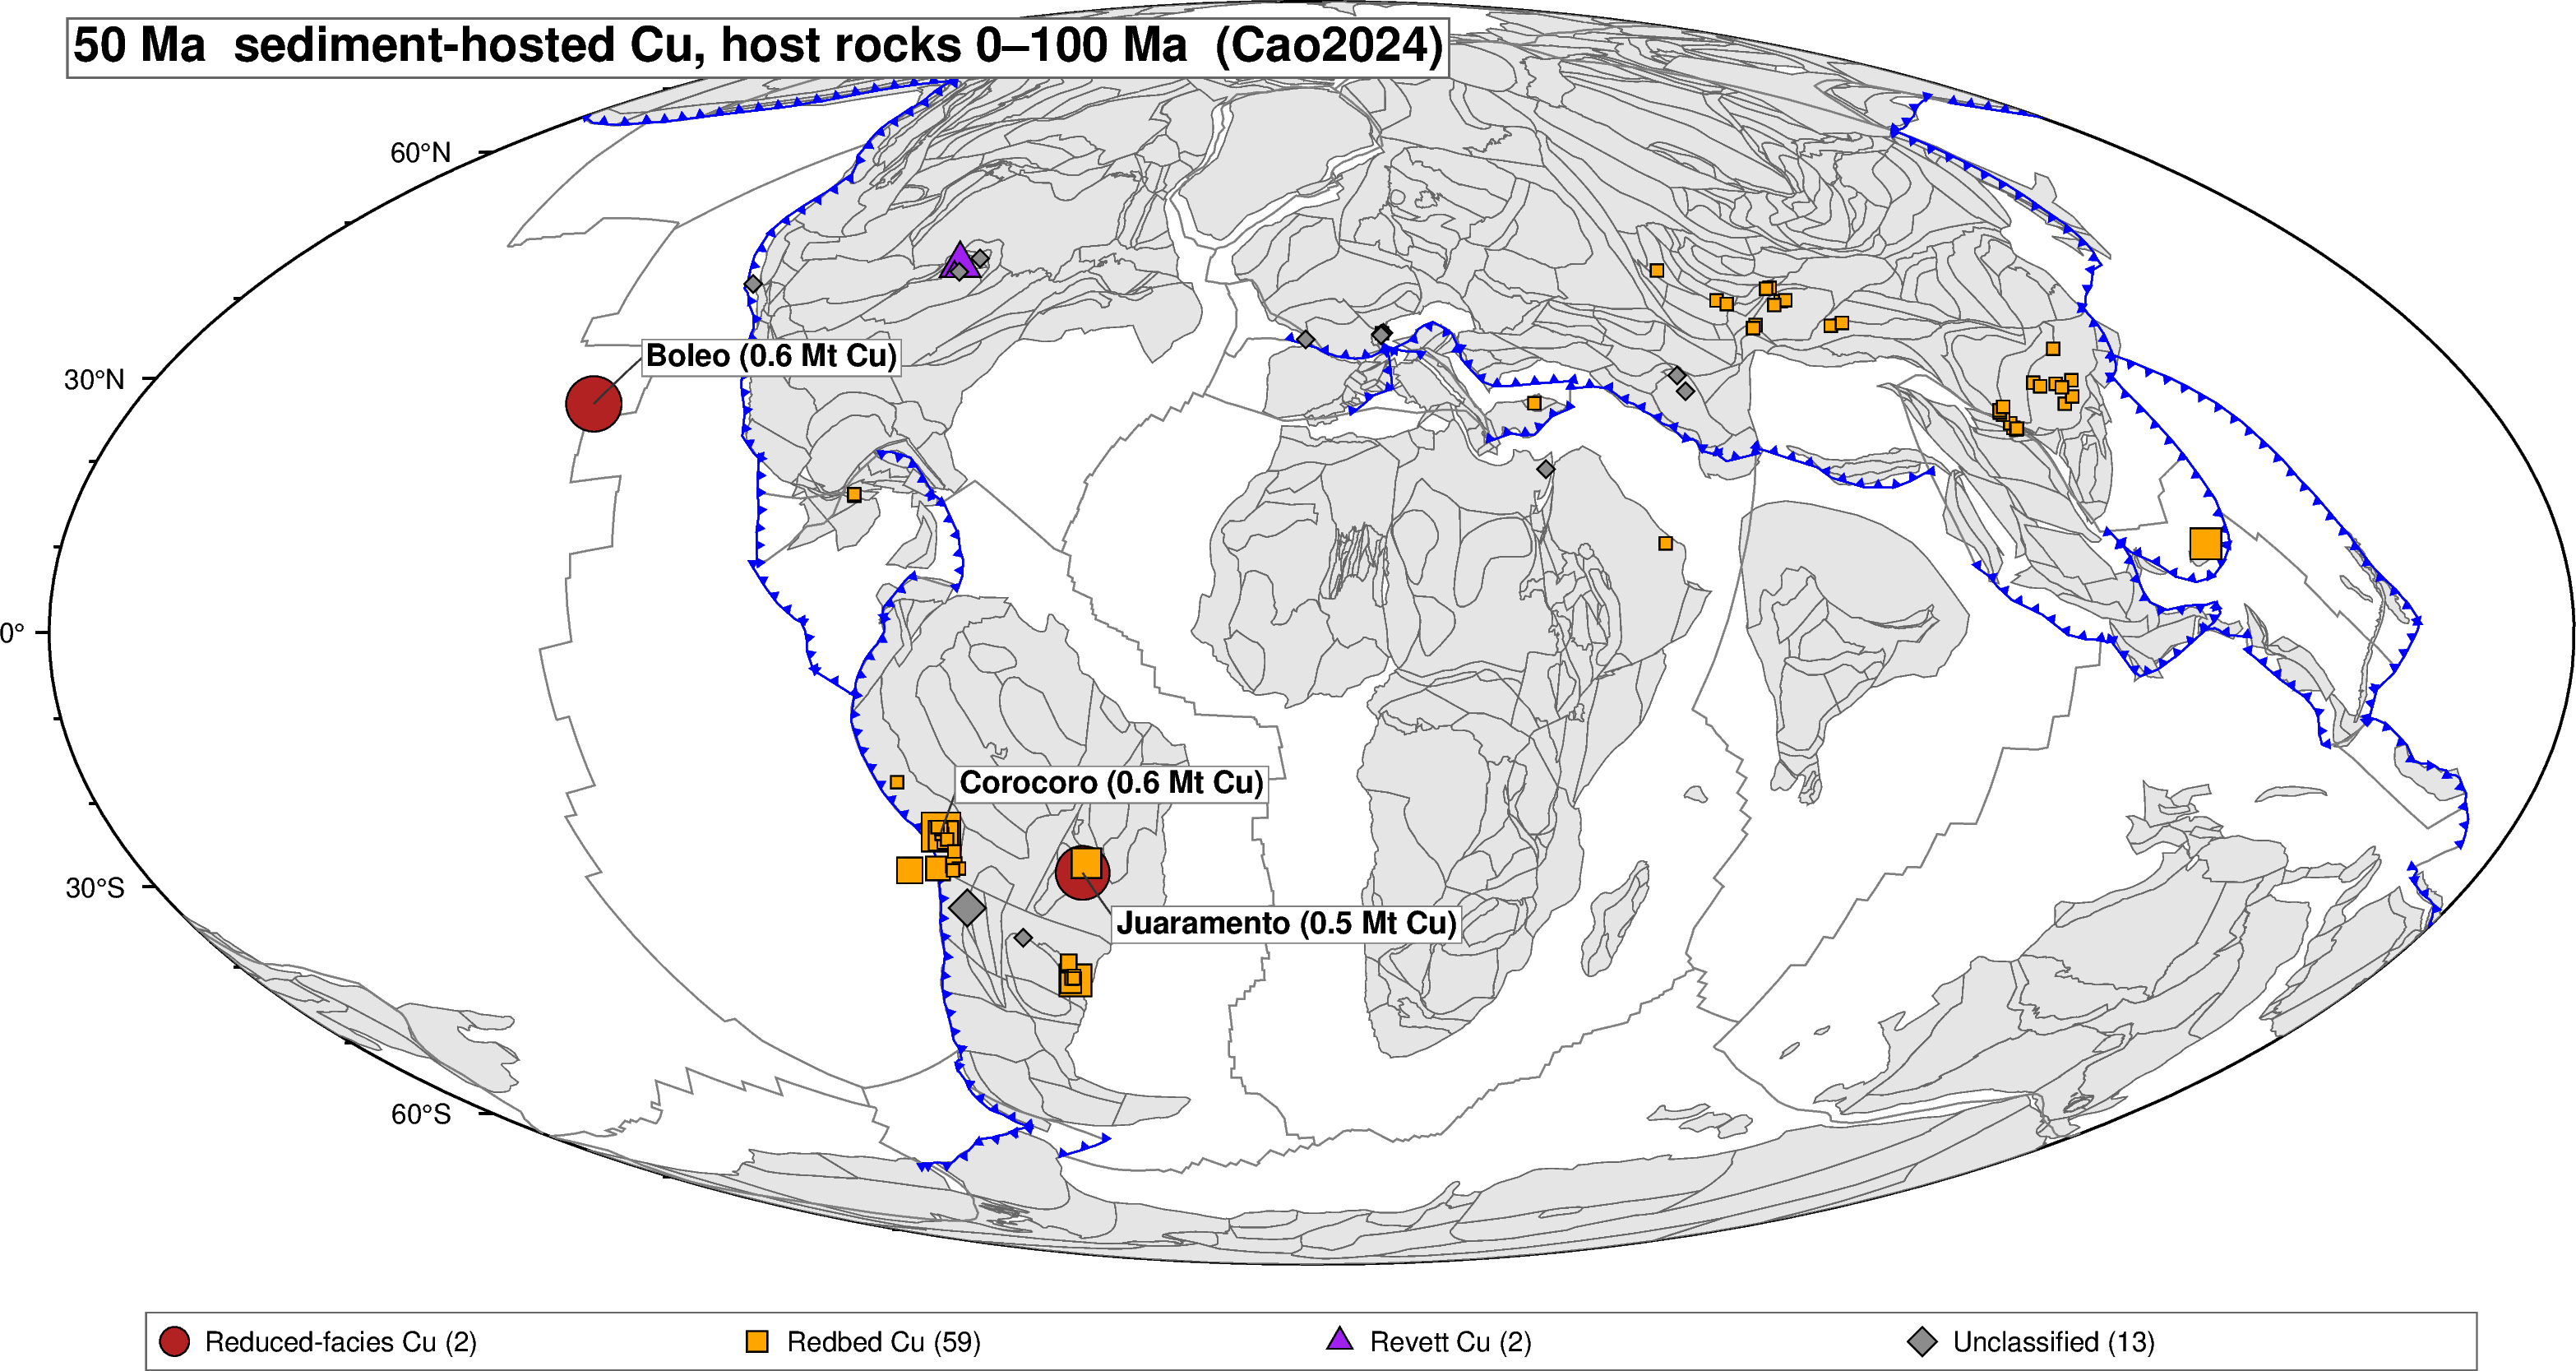

  260 Ma: 203 deposits with host rocks 210–310 Ma  {'Redbed Cu': 112, 'Reduced-facies Cu': 56, 'Unclassified': 27, 'Revett Cu': 8}


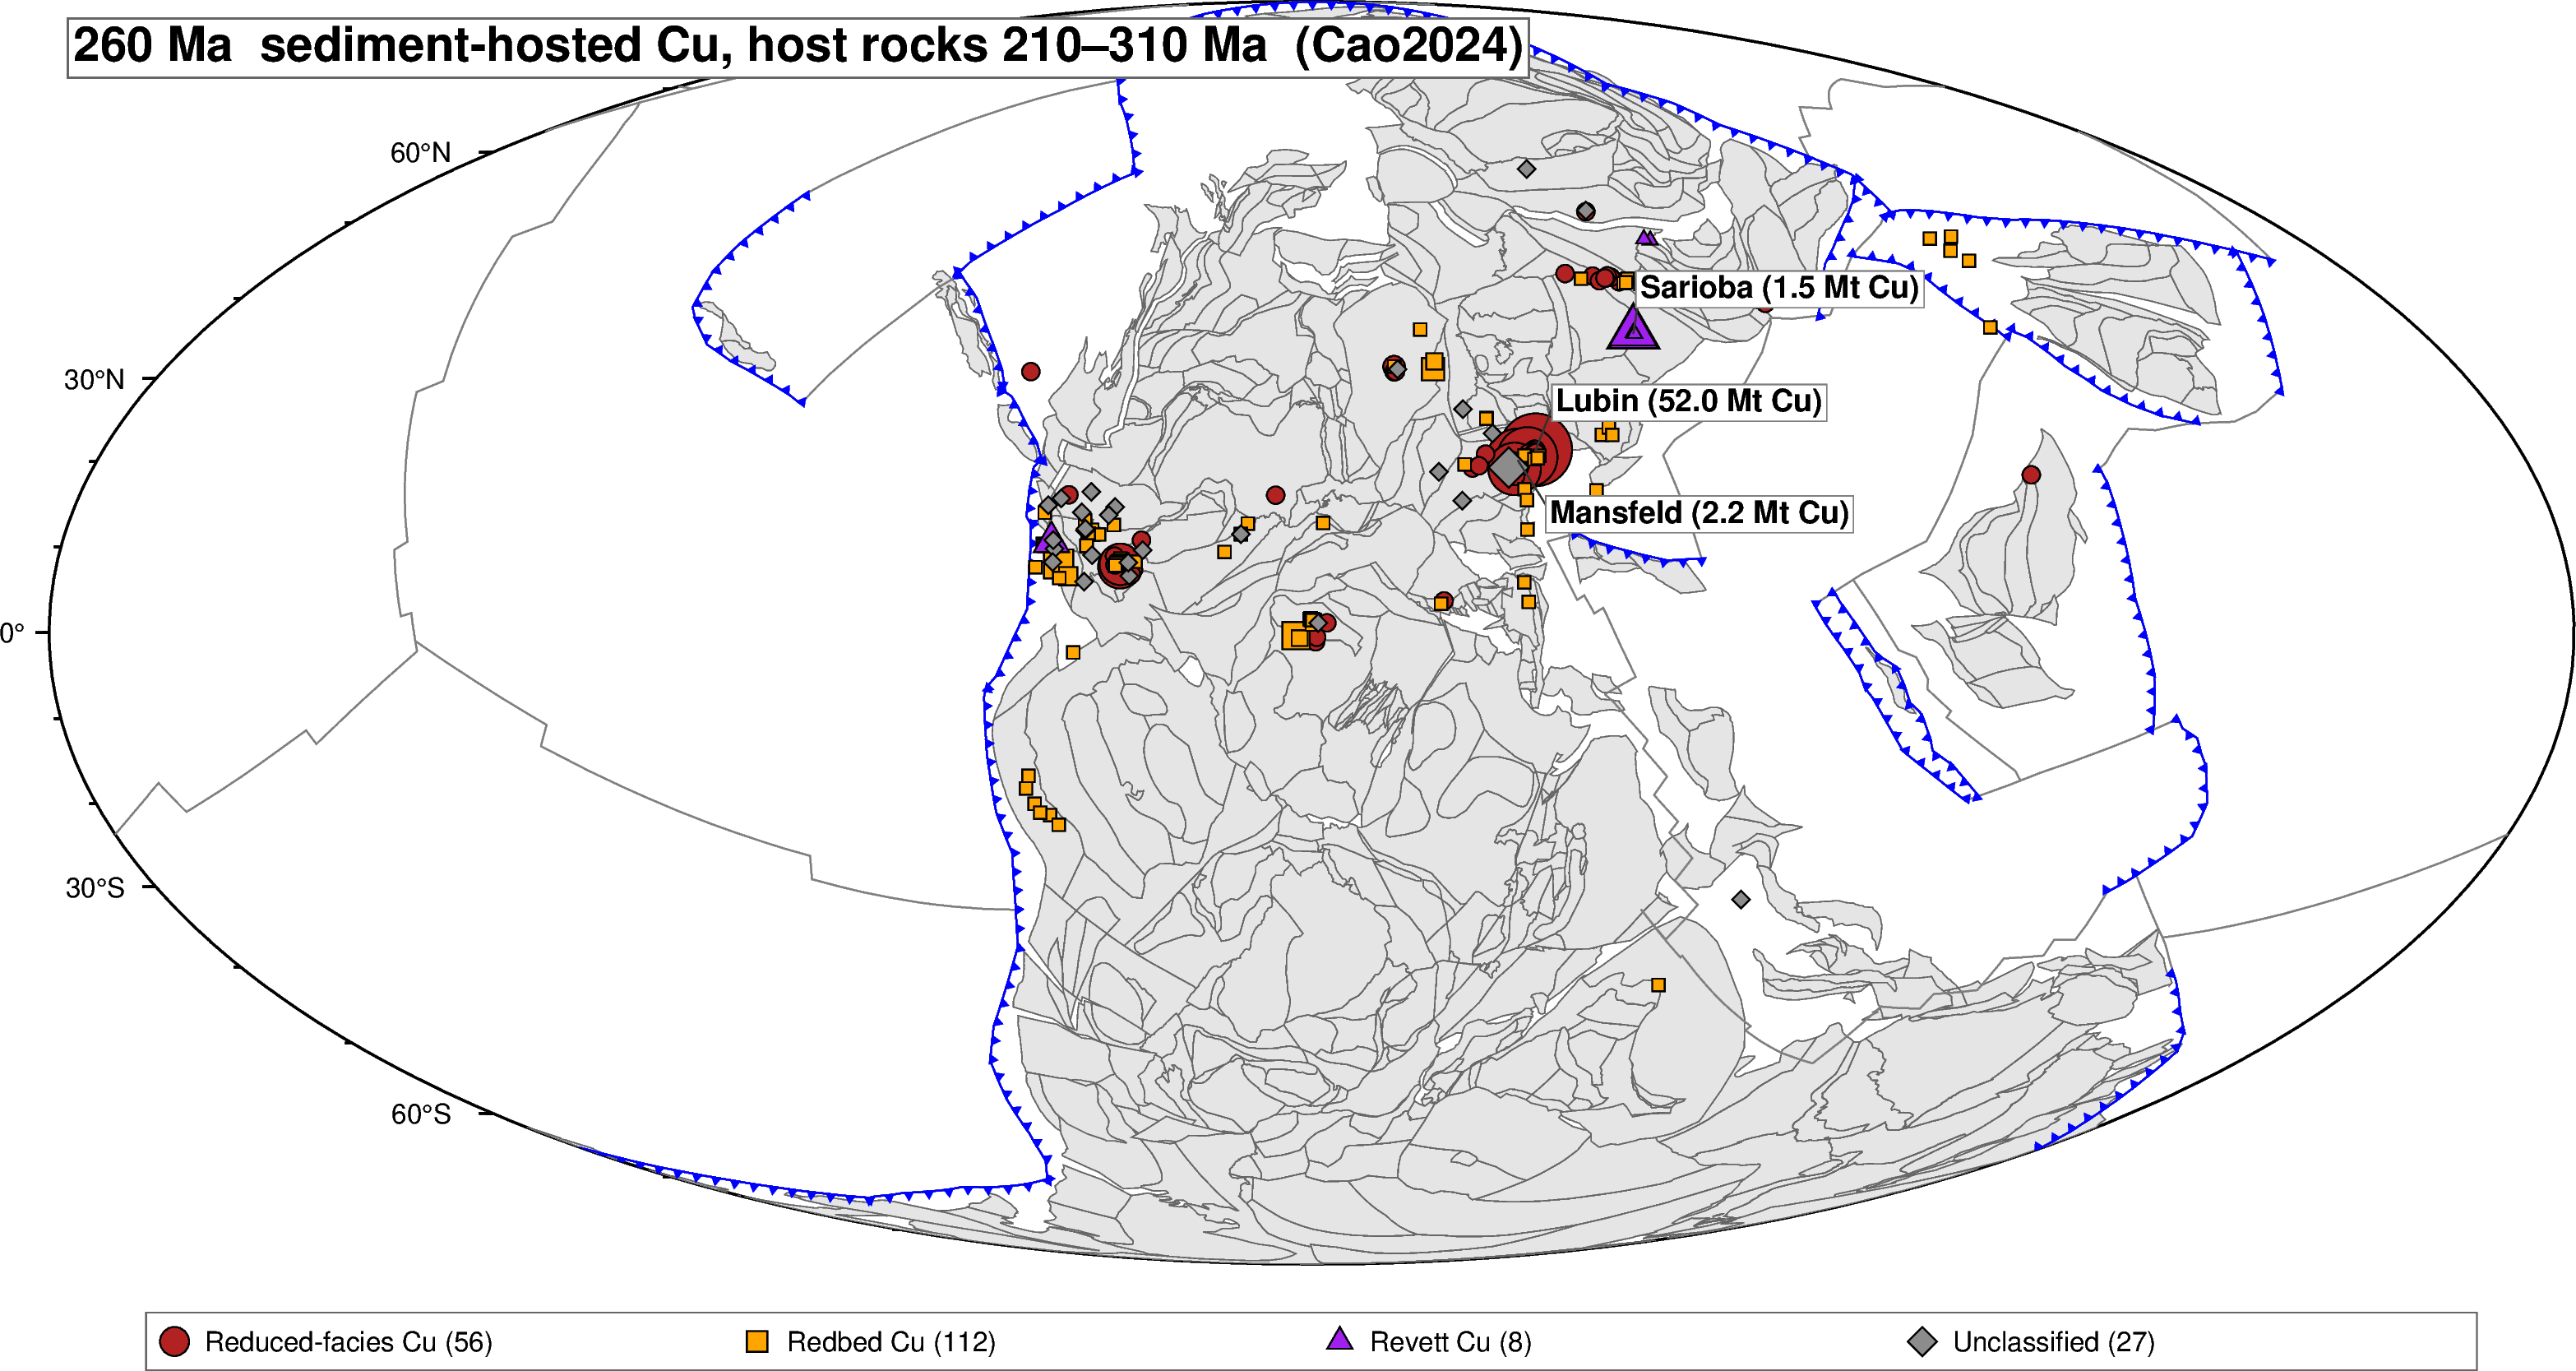

  330 Ma: 203 deposits with host rocks 280–380 Ma  {'Redbed Cu': 88, 'Reduced-facies Cu': 67, 'Unclassified': 24, 'Revett Cu': 24}


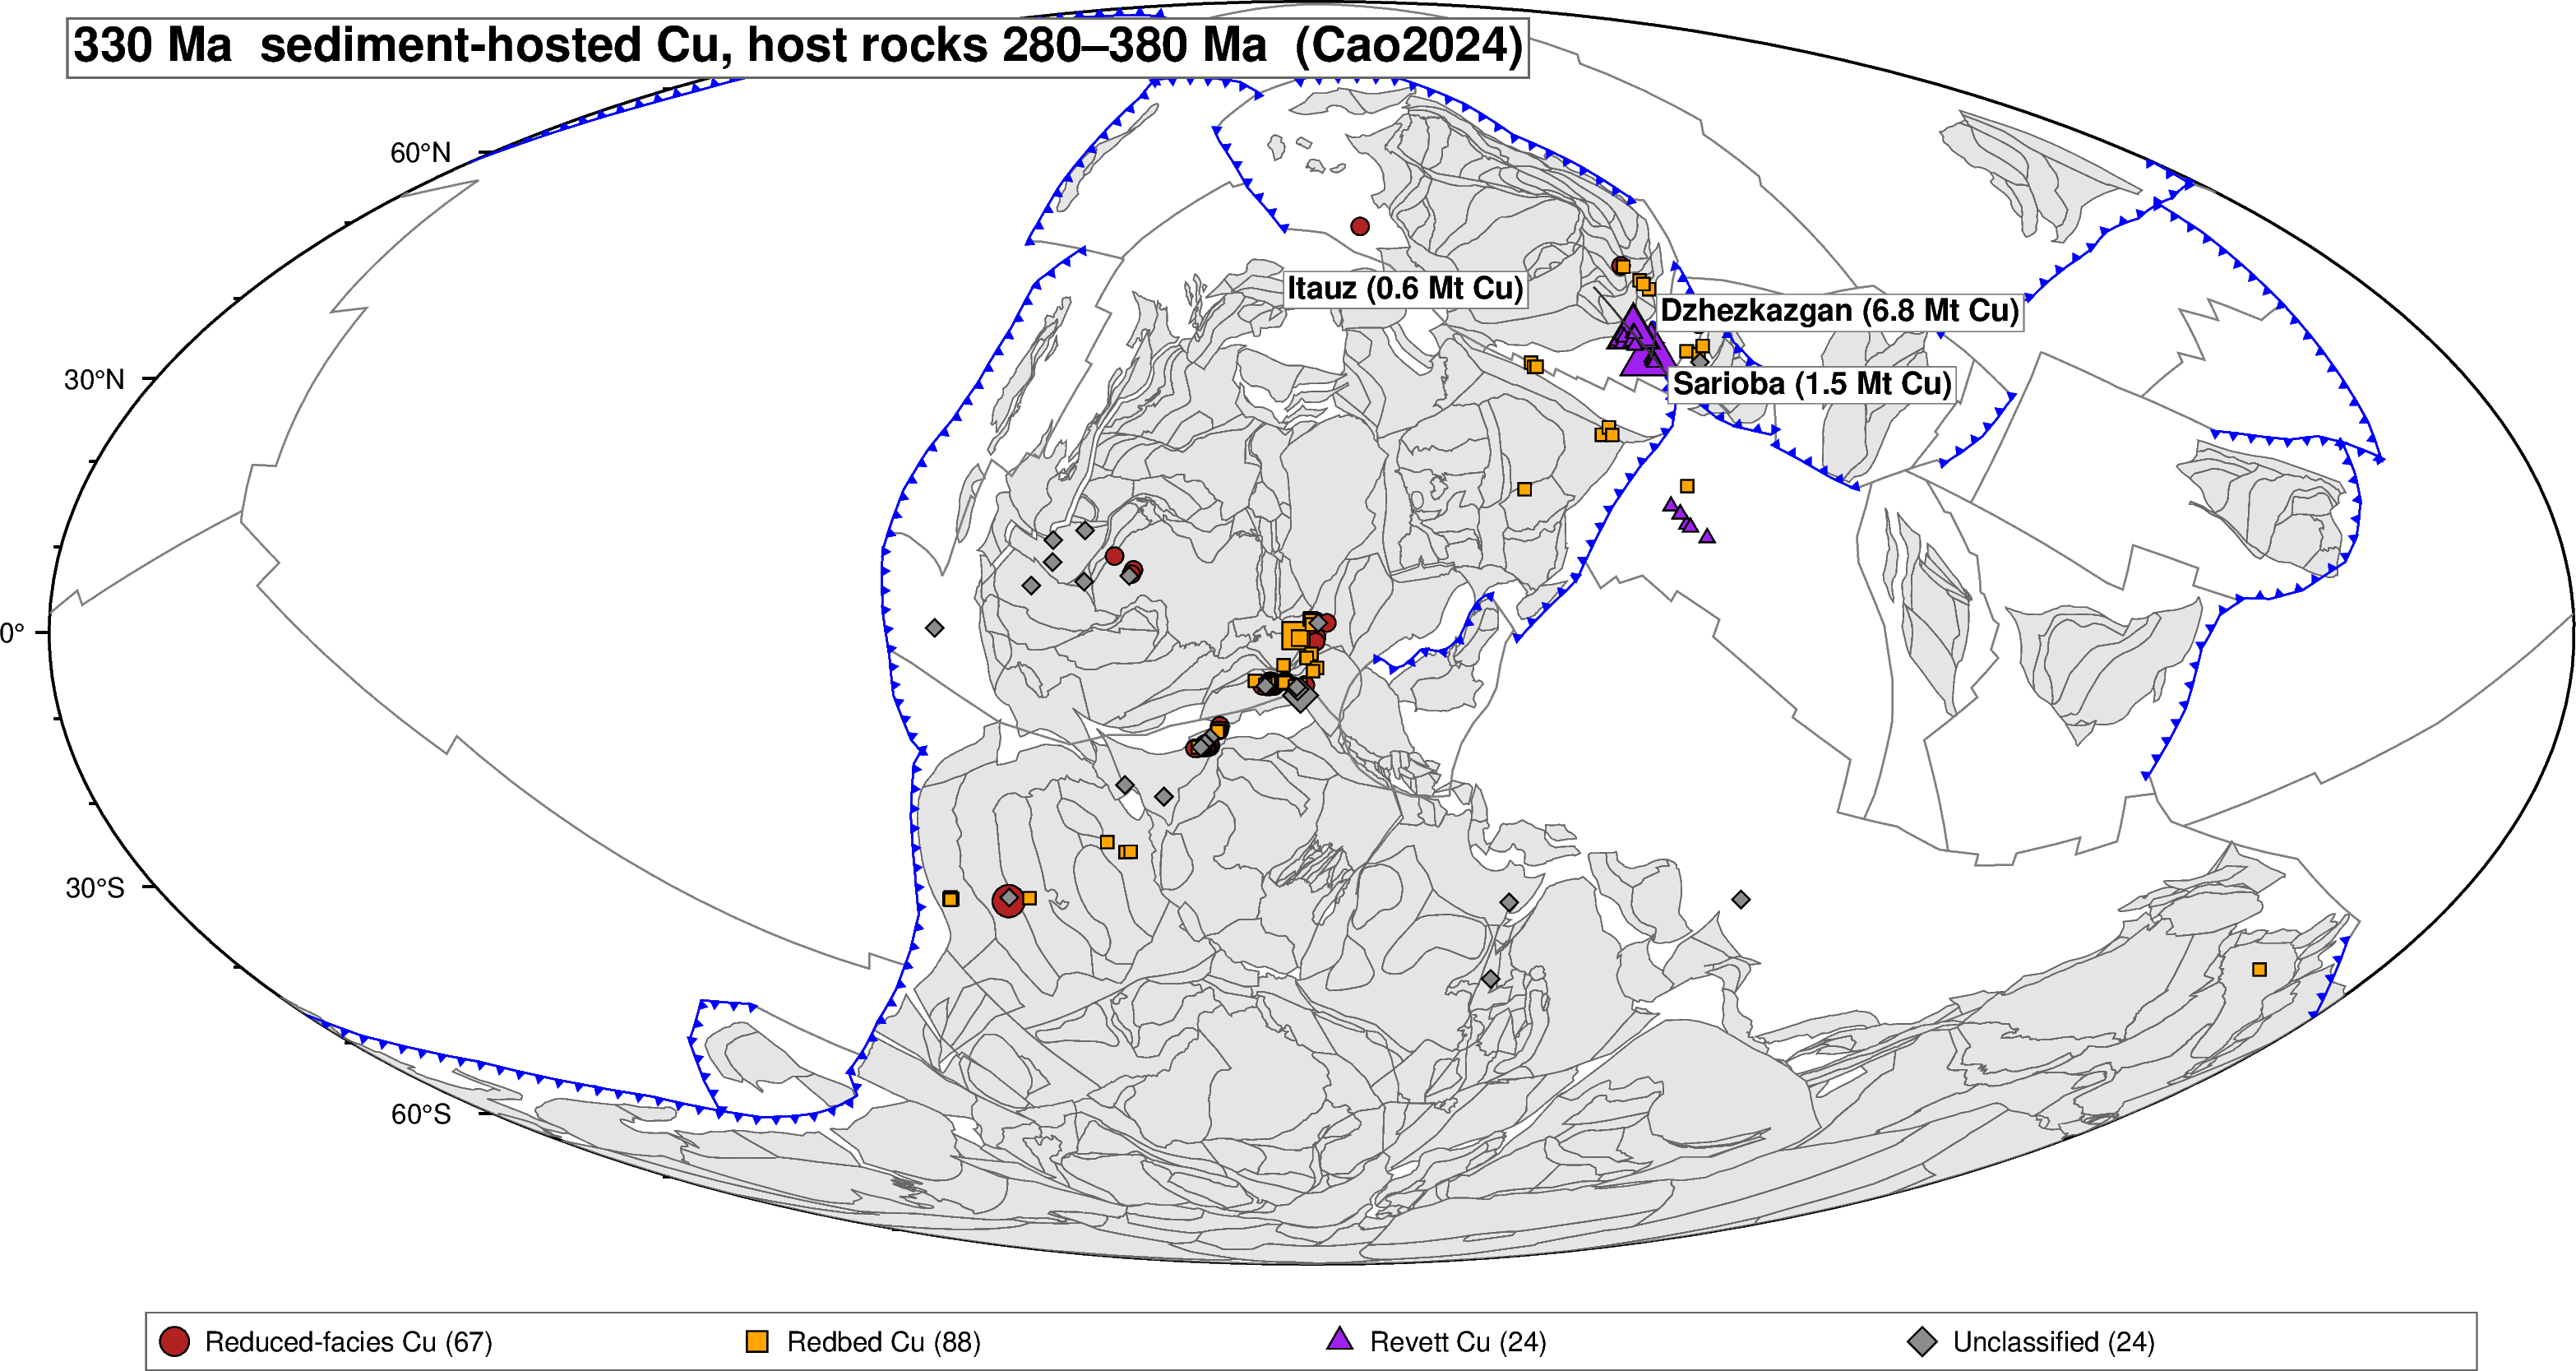

  900 Ma: 62 deposits with host rocks 850–950 Ma  {'Reduced-facies Cu': 38, 'Redbed Cu': 14, 'Unclassified': 10}


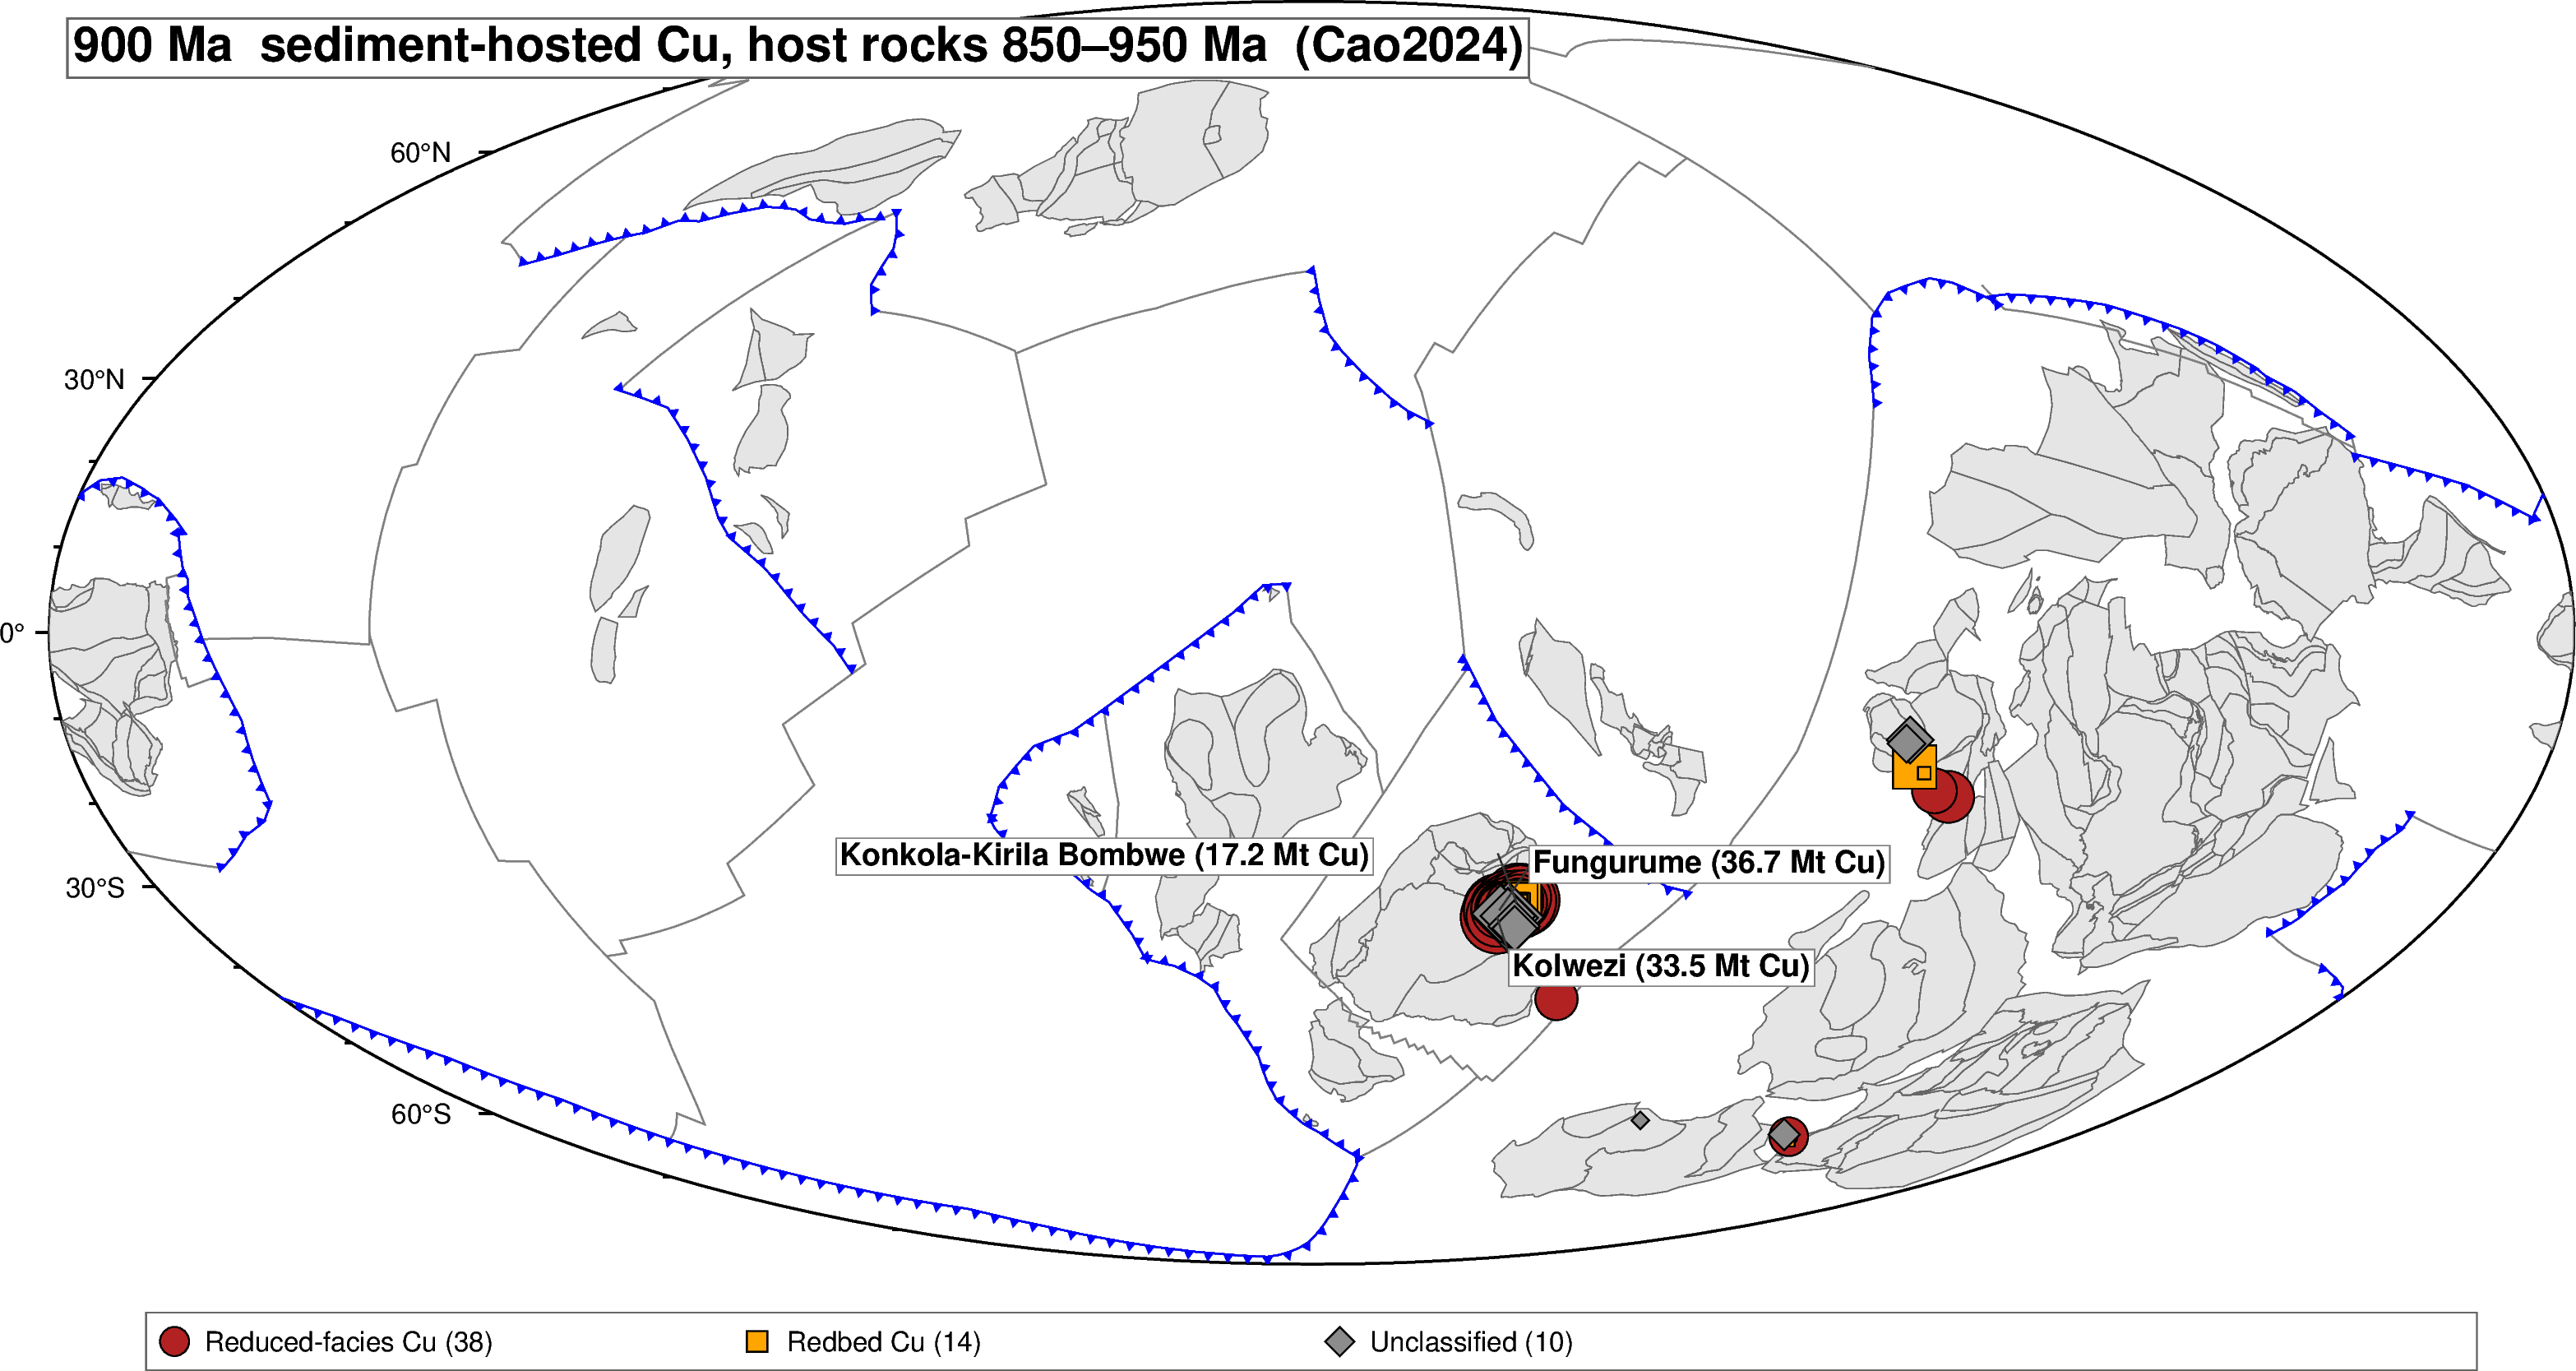

  1100 Ma: 11 deposits with host rocks 1050–1150 Ma  {'Reduced-facies Cu': 11}


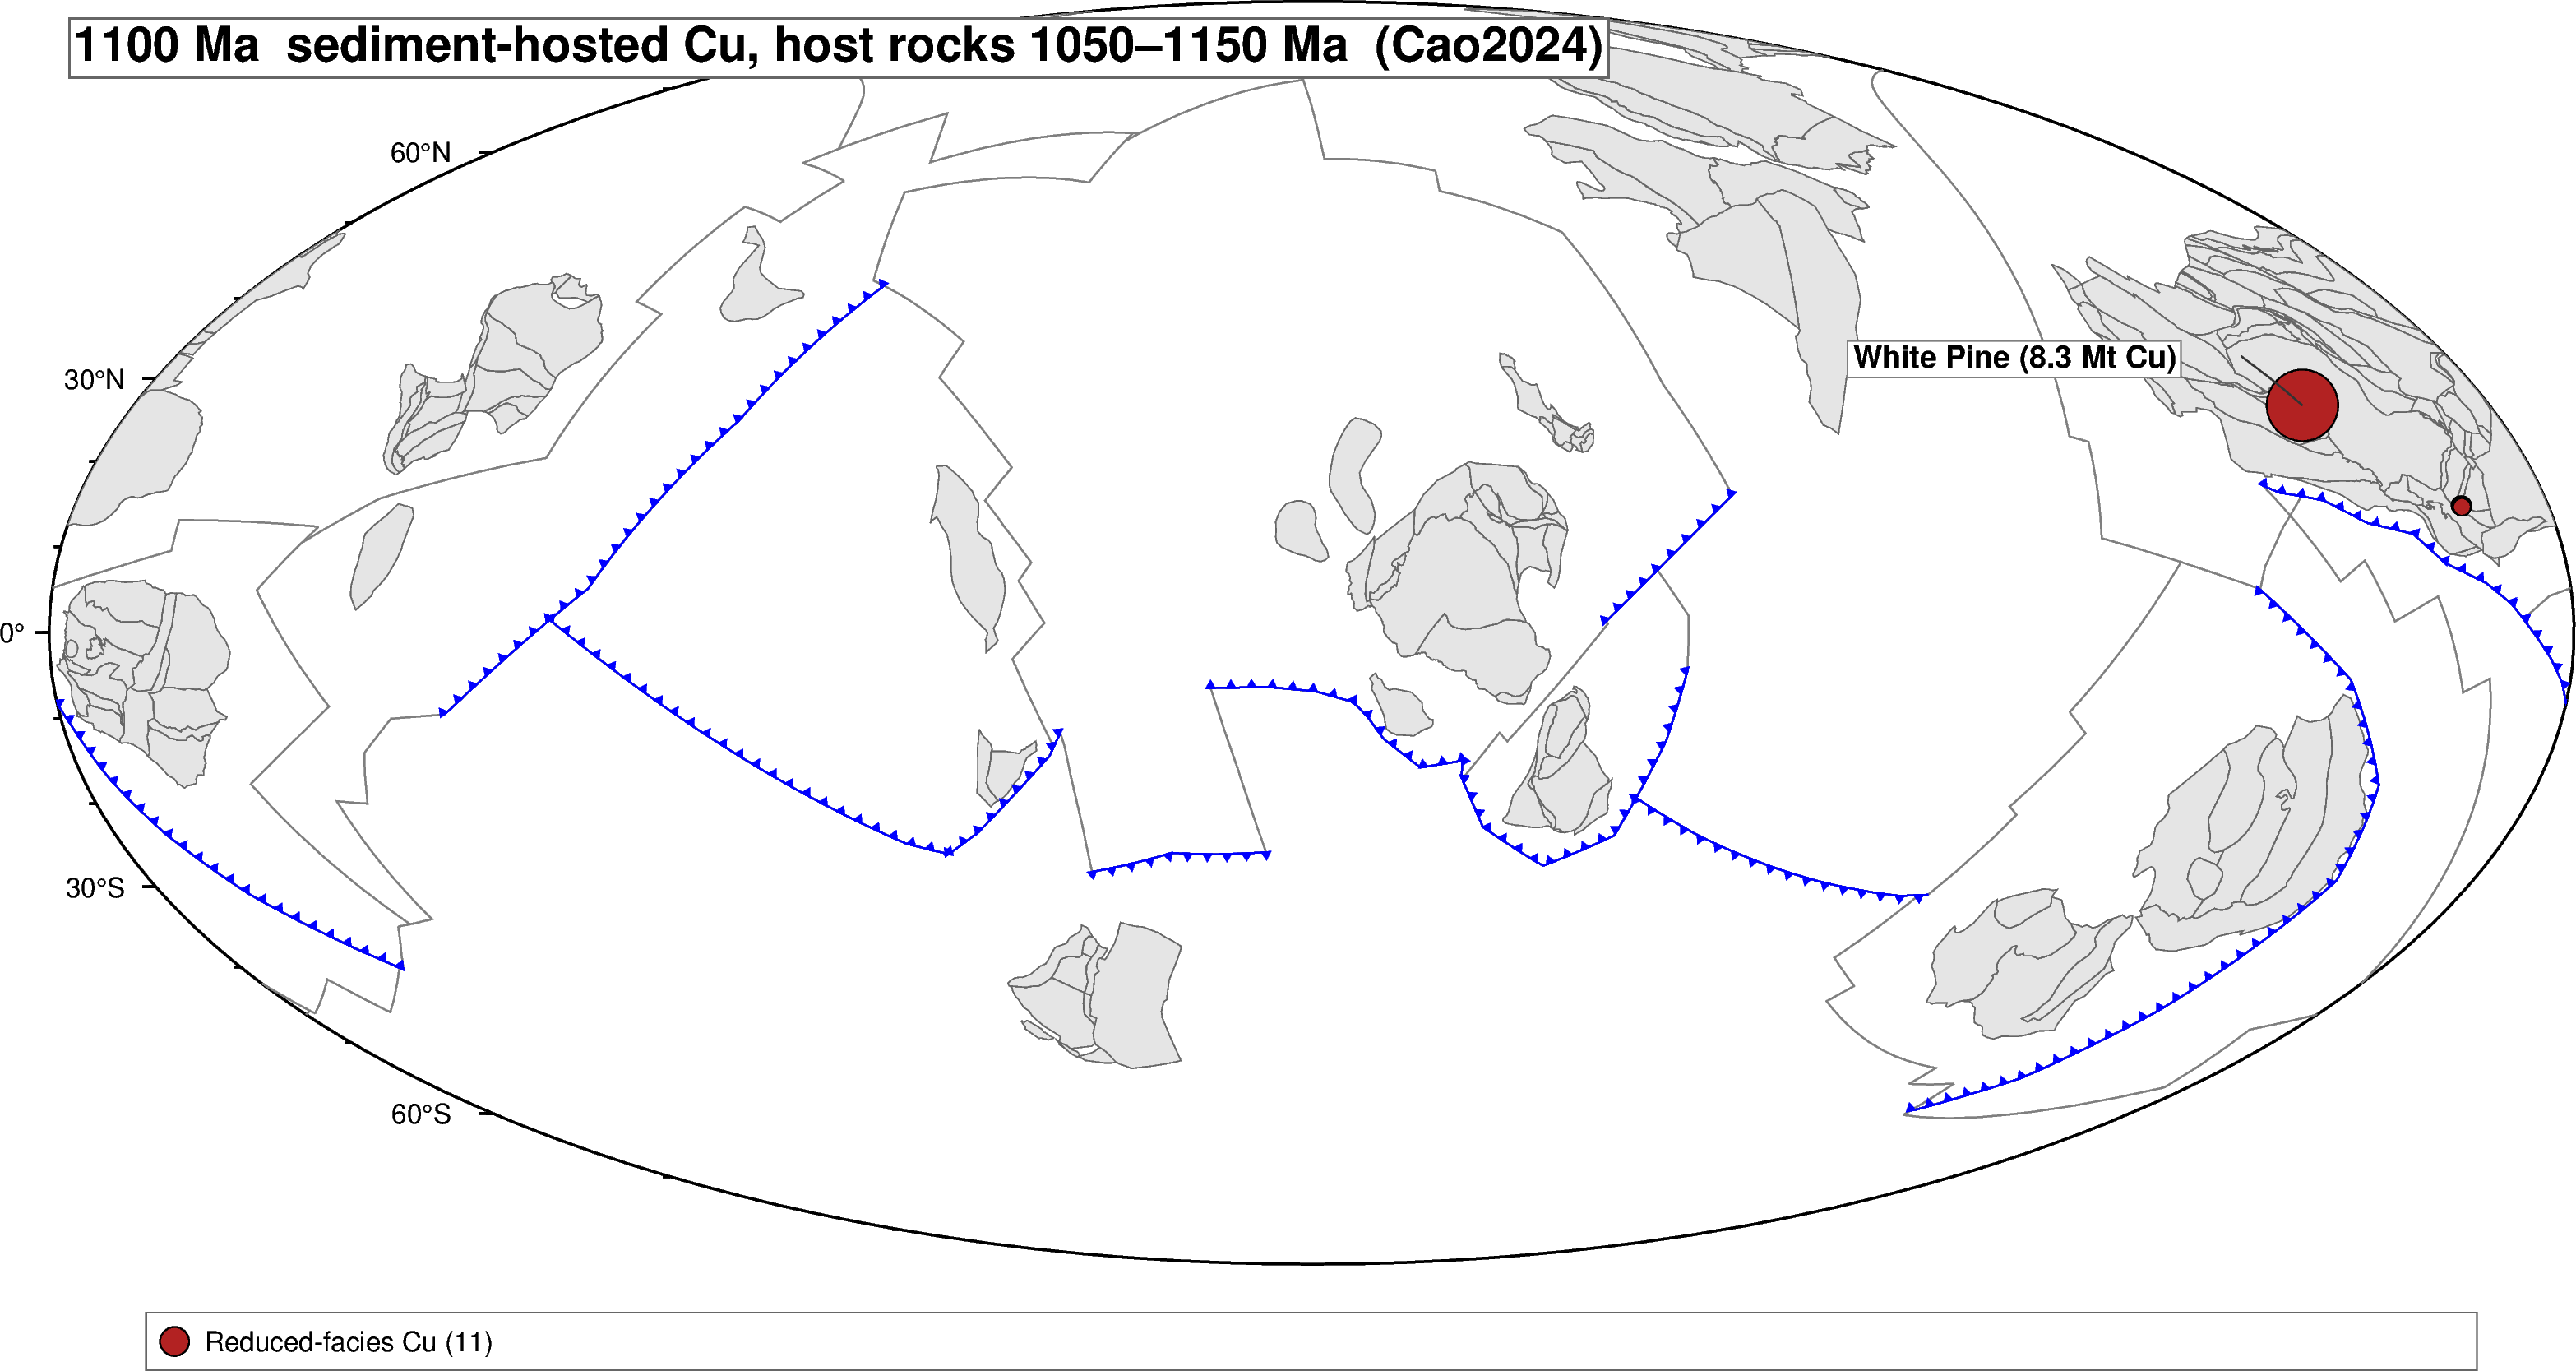

  1450 Ma: 52 deposits with host rocks 1400–1500 Ma  {'Reduced-facies Cu': 18, 'Redbed Cu': 15, 'Unclassified': 12, 'Revett Cu': 7}


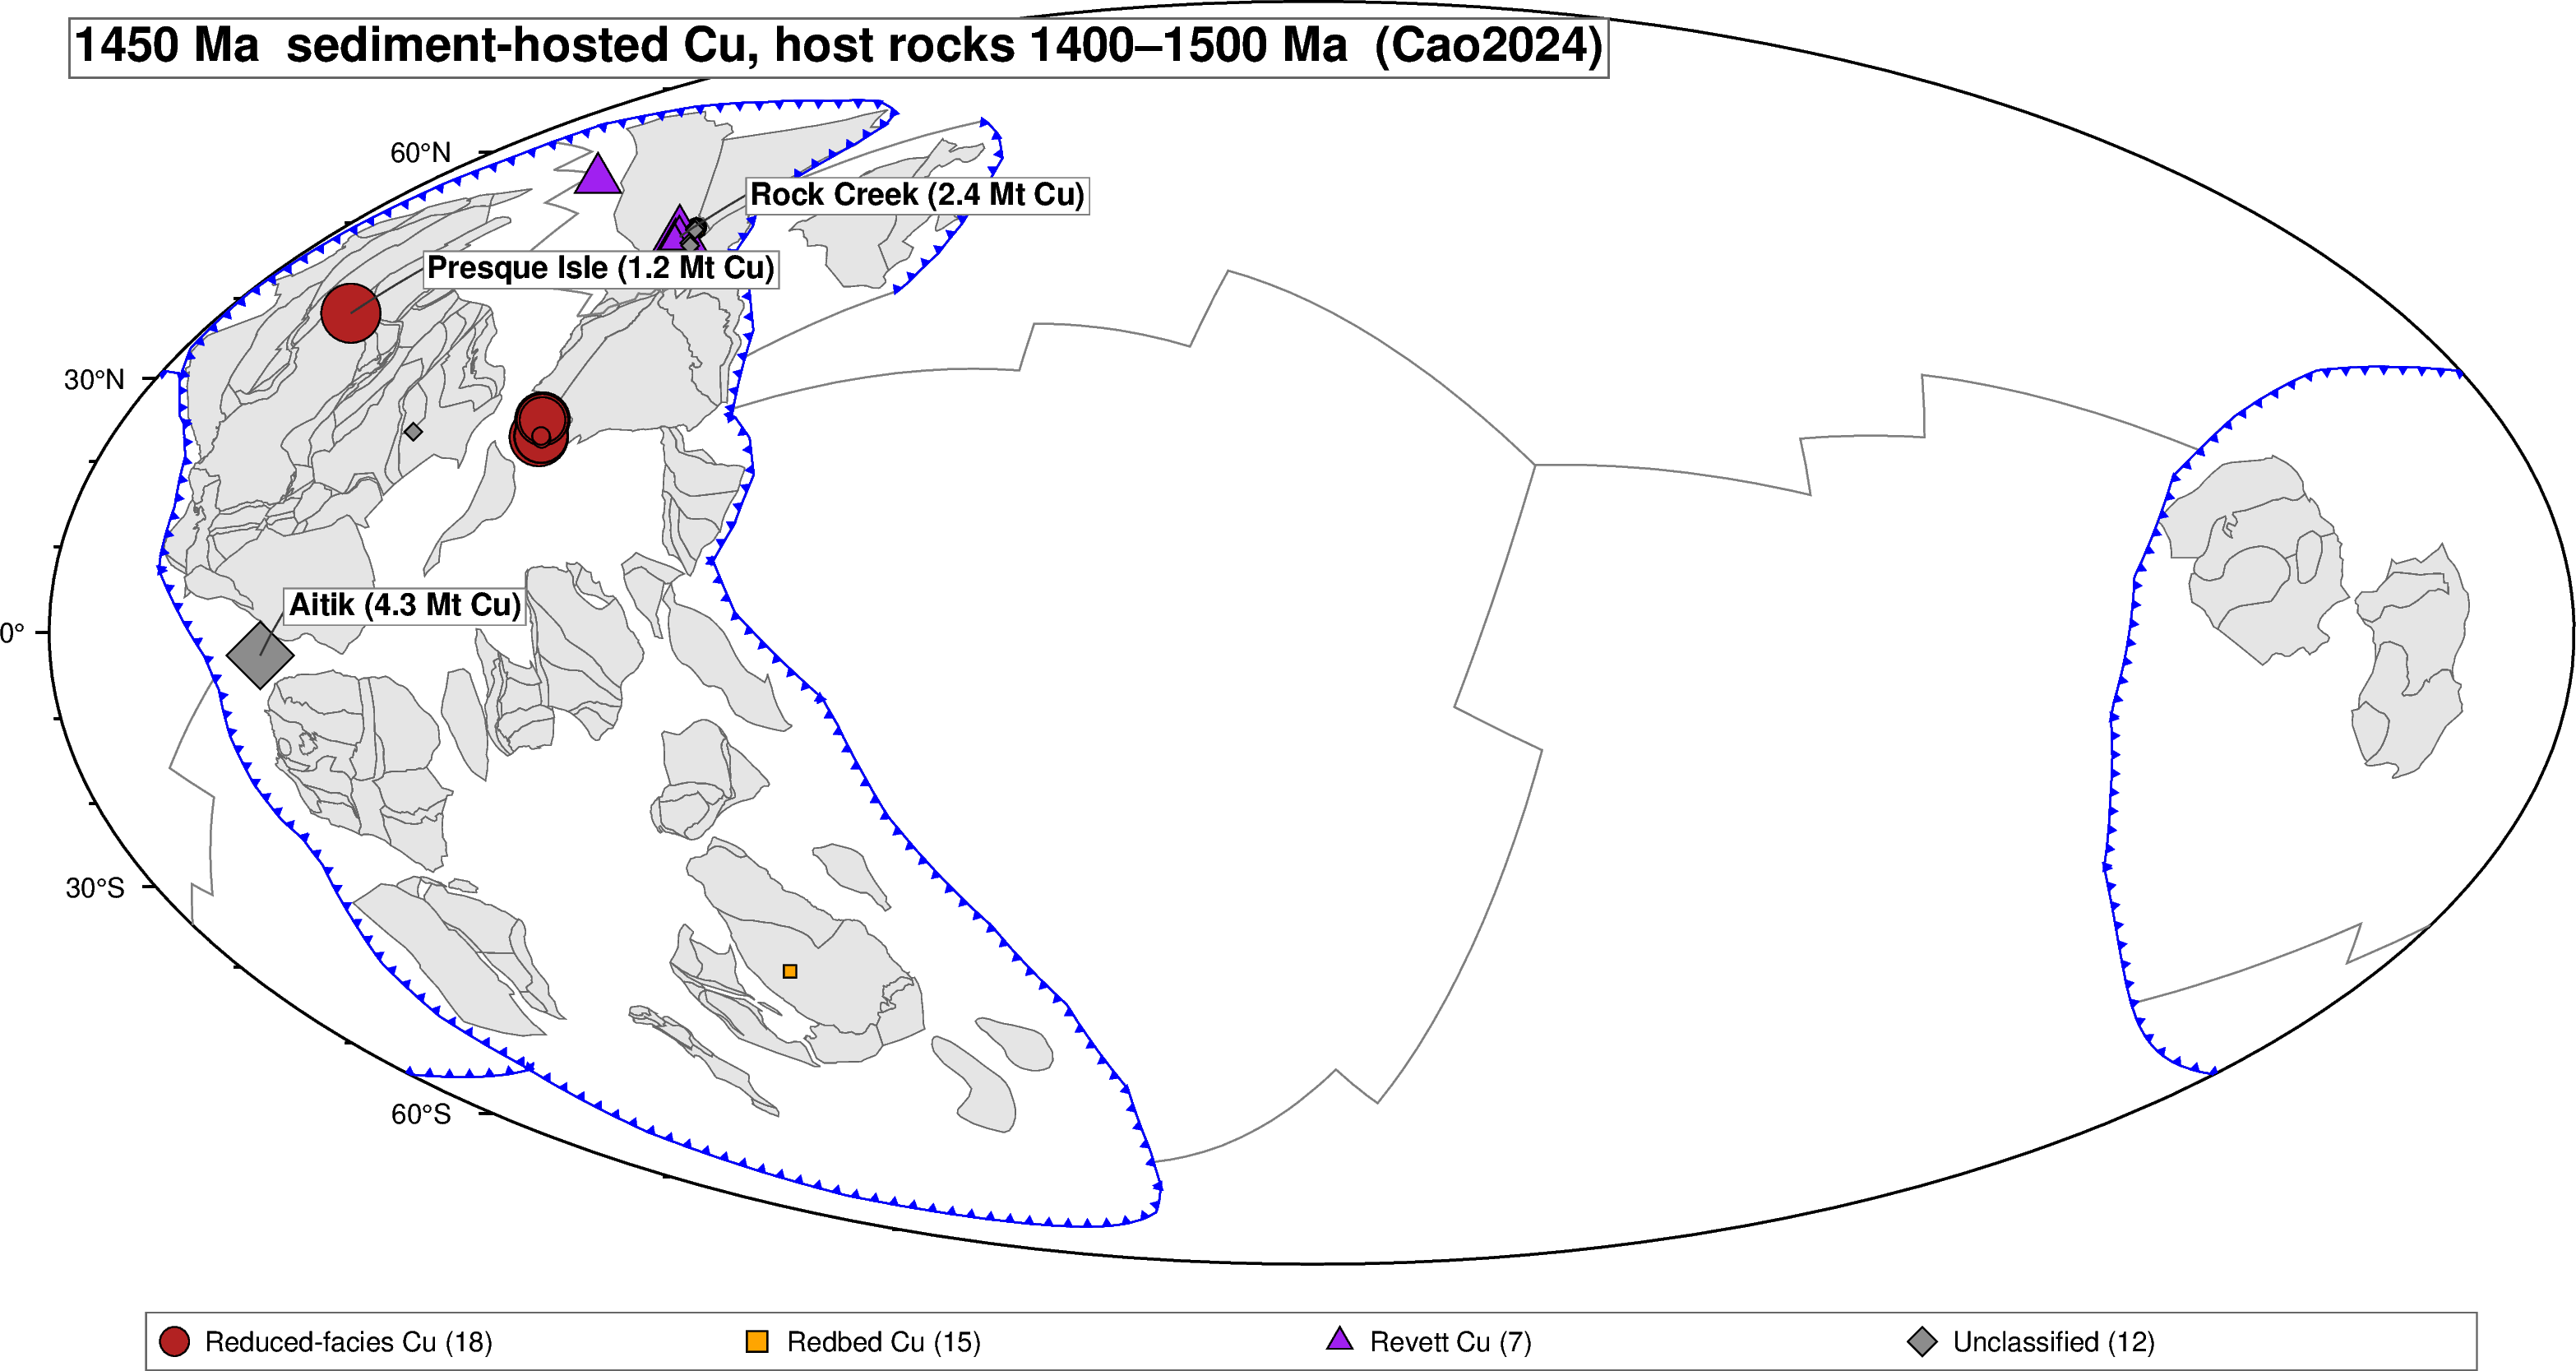

In [5]:
# Cell 4 — one paleogeographic map per snapshot age
# Symbol and colour by the database's subtype; symbol size by contained Cu where reported.
TYPE_STYLE = [   # (subtype, symbol, fill) in legend order
    ("Reduced-facies Cu", "c", "firebrick"),
    ("Redbed Cu",         "s", "orange"),
    ("Revett Cu",         "t", "purple"),
    ("Unclassified",      "d", "gray55"),
]

def symbol_size_cm(cu_mt):
    # 0.18 cm without a reported tonnage; growing with log10(contained Cu, Mt) up to 0.75 cm
    s = 0.30 + 0.15 * np.log10(np.clip(cu_mt, 0.001, 100.0) / 0.01)
    return np.where(np.isfinite(cu_mt), np.clip(s, 0.22, 0.75), 0.18)

def place_labels(fig, rows, font_pt=9):
    """Label each row at the first candidate offset (in degrees) whose label box stays inside the map and
    does not overlap a label already placed; a thin leader line joins label and deposit."""
    placed = []
    cand = [(4, 3), (4, -9), (-4, 3), (-4, -9), (6, 12), (6, -18), (-6, 12), (-6, -18), (8, 21), (8, -27)]
    for r in rows.itertuples():
        text = f"{r.name} ({r.cu_mt:.1f} Mt Cu)"
        # approximate box size in degrees on the 26-cm Mollweide map: a 9-pt character is ~2.4 deg of
        # longitude at the equator, widening towards the poles; the box is ~6 deg high
        w = 2.5 * len(text) * font_pt / 9 / max(np.cos(np.radians(r.paleo_lat)), 0.35)
        h = 6.0
        for dx, dy in cand:
            x0 = r.paleo_lon + dx if dx > 0 else r.paleo_lon + dx - w
            box = (x0, r.paleo_lat + dy, x0 + w, r.paleo_lat + dy + h)
            inside = -178 <= box[0] and box[2] <= 178 and -85 <= box[1] and box[3] <= 85
            if inside and all(box[2] < b[0] or b[2] < box[0] or box[3] < b[1] or b[3] < box[1] for b in placed):
                break
        else:
            raise SystemExit(f"no free label position for {r.name}")
        placed.append(box)
        fig.plot(x=[r.paleo_lon, box[0] if dx > 0 else box[2]], y=[r.paleo_lat, box[1] + h / 2],
                 pen="0.5p,gray20")
        fig.text(text=text, x=box[0], y=box[1] + h / 2, justify="LM", font=f"{font_pt}p,Helvetica-Bold,black",
                 fill="white", pen="0.3p,gray50", clearance="0.06c/0.04c")

for t in SNAPSHOT_TIMES:
    gplot = gplately.PlotTopologies(
        plate_reconstruction=recon,
        coastlines=model.get_coastlines(),
        continents=model.get_continental_polygons(),
        COBs=model.get_COBs(), time=float(t),
        plot_engine=gplately.PygmtPlotEngine(),
        )
    window = dep[(dep.host_age_ma - t).abs() <= TIME_WINDOW_MA].copy()
    window["size_cm"] = symbol_size_cm(window["cu_mt"].to_numpy(float))
    print(f"  {t:.0f} Ma: {len(window)} deposits with host rocks {t - TIME_WINDOW_MA:.0f}–{t + TIME_WINDOW_MA:.0f} Ma  "
          f"{window['deposit_type'].value_counts().to_dict()}")

    fig = pygmt.Figure()
    fig.basemap(region="d", projection="W0/26c", frame=["af"])
    gplot.plot_continents(fig, fill="gray90", pen="0.3p,gray40")
    gplot.plot_all_topological_sections(fig, pen="0.5p,gray50")
    try:
        gplot.get_subduction_direction()
        gplot.plot_subduction_teeth(fig, color="blue")
    except Exception:
        pass                                     # no resolved subduction zones at this age
    first = True
    for type_name, sym, fill_col in TYPE_STYLE:
        sub = window[window["deposit_type"] == type_name].sort_values("size_cm", ascending=False)
        if not len(sub):
            continue
        fig.plot(x=sub["paleo_lon"], y=sub["paleo_lat"], size=sub["size_cm"], style=f"{sym}c",
                 fill=fill_col, pen="0.4p,black",
                 label=f"{type_name} ({len(sub)})+S0.3c" + ("+N4" if first else ""))
        first = False
    if len(window):
        fig.legend(position="JBC+jTC+o0/0.5c+w24c", box="+gwhite+p0.4p,gray40")
    # labels for the largest deposits (contained Cu), placed without overlaps
    place_labels(fig, window.nlargest(N_LABELS, "cu_mt").dropna(subset=["cu_mt"]))
    fig.text(text=f"{t:.0f} Ma  sediment-hosted Cu, host rocks {t - TIME_WINDOW_MA:.0f}–{t + TIME_WINDOW_MA:.0f} Ma  ({MODEL_NAME})",
             position="TL", offset="0.25c/-0.25c", justify="TL",
             font="14p,Helvetica-Bold,black", fill="white", pen="0.6p,gray40")
    fig.show(width=1300)
    display(HTML('<div style="height:1cm"></div>'))

## What the figures show

One paleogeographic map per age in `SNAPSHOT_TIMES`. Each symbol is one deposit of the USGS database whose host rocks are within `TIME_WINDOW_MA` (50 Myr) of the map age, drawn at its position at its own host-rock age on top of the plate boundaries (grey) and subduction zones (blue teeth) of the map age. Circles, squares, triangles and diamonds are the database's reduced-facies, redbed, Revett and unclassified subtypes; larger symbols mean more contained copper, and the smallest symbols are deposits without a reported tonnage. The `N_LABELS` deposits with the most contained copper are named.

**Reading the maps.** Look at where the deposits sit relative to the contemporaneous subduction zones: inside continents and on basin margins, rather than in the belts next to trenches where the porphyry deposits of K01 and K02 cluster. The 900 Ma map holds the Central African Copperbelt (Kolwezi, Fungurume, Konkola), the 260 Ma map the Kupferschiefer (Lubin, Mansfeld), the 330 Ma map Dzhezkazgan, the 1100 Ma map White Pine and the 1450 Ma map the Revett deposits of the Belt–Purcell basin.

## Extend this

- **Animate.** Loop over ages from 0 to 1800 Ma in 50 Myr steps and stitch the frames with `pygmt.movie` or ffmpeg: the deposits appear as their host basins form.
- **Subtypes.** Plot one subtype at a time (`deposit_type == "Redbed Cu"`, for example) to see where each formed.
- **Paleo-distance to the nearest trench.** K02 computes, for porphyry deposits, the paleo-distance to the nearest contemporaneous trench and the convergence rate there. Run the same function on this table to compare sediment-hosted and porphyry Cu directly.
- **Paleoclimate.** Redbed Cu needs oxidised, arid-zone sediment. Overlay the climate-sensitive lithologies of J01 at the matching age to test where the redbed deposits sat.

## References

- Cox, D.P., Lindsey, D.A., Singer, D.A., Moring, B.C. & Diggles, M.F. (2003, rev. 2007). Sediment-hosted copper deposits of the world: deposit models and database. *U.S. Geological Survey Open-File Report* 03-107, version 1.3. https://pubs.usgs.gov/of/2003/of03-107/
- Hitzman, M., Kirkham, R., Broughton, D., Thorson, J. & Selley, D. (2005). The sediment-hosted stratiform copper ore system. *Economic Geology One Hundredth Anniversary Volume*, 609-642. https://doi.org/10.5382/AV100.19
- Hitzman, M.W., Selley, D. & Bull, S. (2010). Formation of sedimentary rock-hosted stratiform copper deposits through Earth history. *Economic Geology* 105(3), 627-639. https://doi.org/10.2113/gsecongeo.105.3.627
- Cao, X., Collins, A.S., Pisarevsky, S., Flament, N., Li, S., Hasterok, D. & Müller, R.D. (2024). Earth's tectonic and plate boundary evolution over 1.8 billion years. *Geoscience Frontiers* 15, 101922. https://doi.org/10.1016/j.gsf.2024.101922
- Mather, B.R., Müller, R.D., Zahirovic, S., Cannon, J., Chin, M., Ilano, L., Wright, N.M., Alfonso, C., Williams, S., Tetley, M. & Merdith, A. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geoscience Data Journal* 11(1), 3-10. https://doi.org/10.1002/gdj3.185